### First attempt was at the following parameters: 
####   epochs=60,
####    imgsz=640,
####    batch=8, 

In [ ]:
import pandas as pd
from pathlib import Path

# Find the latest training run
runs = sorted(Path("runs/detect").glob("gun_detector*"), key=lambda f: f.stat().st_mtime)
latest = runs[-1]
results_csv = latest / "results.csv"

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()  # remove whitespace from column names
print(df[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)"]].to_string())

Created config file at dataset/data.yaml
Using weights: runs\detect\gun_detector-15\weights\best.pt


### Model Training Code - Run this to start
#### Parameters:
##### Number of epochs (epochs)

##### In machine learning, one “epoch” is one single pass through the full training dataset. Setting the number of epochs dictates how long the model will train for. The best amount of epochs to use depends on the size of the dataset and the model architecture. If your dataset has less than 200 images, a good starting point is 60 epochs. If your dataset has more than 200 images, a good starting point is 40 epochs.

##### Resolution (imgsz)

##### Resolution has a large impact on the speed and accuracy of the model: a lower resolution model will have higher speed but less accuracy. YOLO models are typically trained and inferenced at a 640x640 resolution. However, if you want your model to run faster or know you will be working with low-resolution images, try using a lower resolution like 480x480.

In [10]:
import os
from pathlib import Path

label_dir = Path("dataset/labels/train")
image_dir = Path("dataset/images/train")

issues = []
for label_file in label_dir.glob("*.txt"):
    with open(label_file) as f:
        lines = f.readlines()
    if len(lines) == 0:
        issues.append(f"EMPTY label: {label_file.name}")
        continue
    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            issues.append(f"BAD format in {label_file.name}: {line.strip()}")
            continue
        cx, cy, w, h = map(float, parts[1:])
        if not (0 < cx < 1 and 0 < cy < 1 and 0 < w < 1 and 0 < h < 1):
            issues.append(f"OUT OF RANGE in {label_file.name}: cx={cx} cy={cy} w={w} h={h}")

if issues:
    print(f"Found {len(issues)} issues:")
    for i in issues[:20]:  # show first 20
        print(" ", i)
else:
    print("✅ All labels look valid!")

✅ All labels look valid!


In [ ]:
import torch

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"Number of GPUs: {torch.cuda.device_count()}")
else:
    print("⚠️ CUDA not available - training will use CPU (much slower)")

In [ ]:
import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):
    if not os.path.exists(path_to_classes_txt):
        print(f'classes.txt not found at {path_to_classes_txt}')
        return
    with open(path_to_classes_txt, 'r') as f:
        classes = [line.strip() for line in f if line.strip()]
    
    data = {
        'path': 'dataset',
        'train': 'images/train',
        'val': 'images/val',
        'nc': len(classes),
        'names': classes
    }
    with open(path_to_data_yaml, 'w') as f:
        yaml.dump(data, f, sort_keys=False)
    print(f'✅ Created data.yaml with classes: {classes}')

create_data_yaml('dataset/classes.txt', 'dataset/data.yaml')

✅ Expanded 112 images → 560 total training images


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

model.train(
    data=r"dataset/data.yaml",
    epochs=150,
    patience=50,
    imgsz=640,
    batch=4,
    optimizer="SGD",
    lr0=0.0001,
    lrf=0.01,
    warmup_epochs=5,
    weight_decay=0.0005,
    dropout=0.1,
    augment=True,
    mosaic=1.0,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    pretrained=True,
    device=0,  # GPU device (0 = first GPU, or set to CPU if no GPU)
    name="gun_detector"
)

New https://pypi.org/project/ultralytics/8.4.67 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.56  Python-3.12.10 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000230EFD7D400>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

### Model Testing Code


#### The model has been trained; now it's time to test it! The commands below run the model on the images in the validation folder and then display the results for the first 10 images. This is a good way to confirm your model is working as expected. Click Play on the blocks below to see how your model performs.



image 1/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene1_12.png: 640x640 5 guns, 99.0ms
image 2/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene1_4.png: 640x640 5 guns, 9.5ms
image 3/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene1_5.png: 640x640 5 guns, 10.8ms
image 4/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene1_6.png: 640x640 5 guns, 8.9ms
image 5/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene2_19.png: 640x640 5 guns, 8.2ms
image 6/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene2_2.png: 640x640 5 guns, 10.5ms
image 7/29 c:\Users\Andrew\Documents\AI ML\Python AI ML Class Capstone\Capstone\dataset\images\val\Scene2_21.png: 640x640 5 guns, 11.5ms
image 8/29 c:\Users\Andrew\Documents\AI ML\Pyth

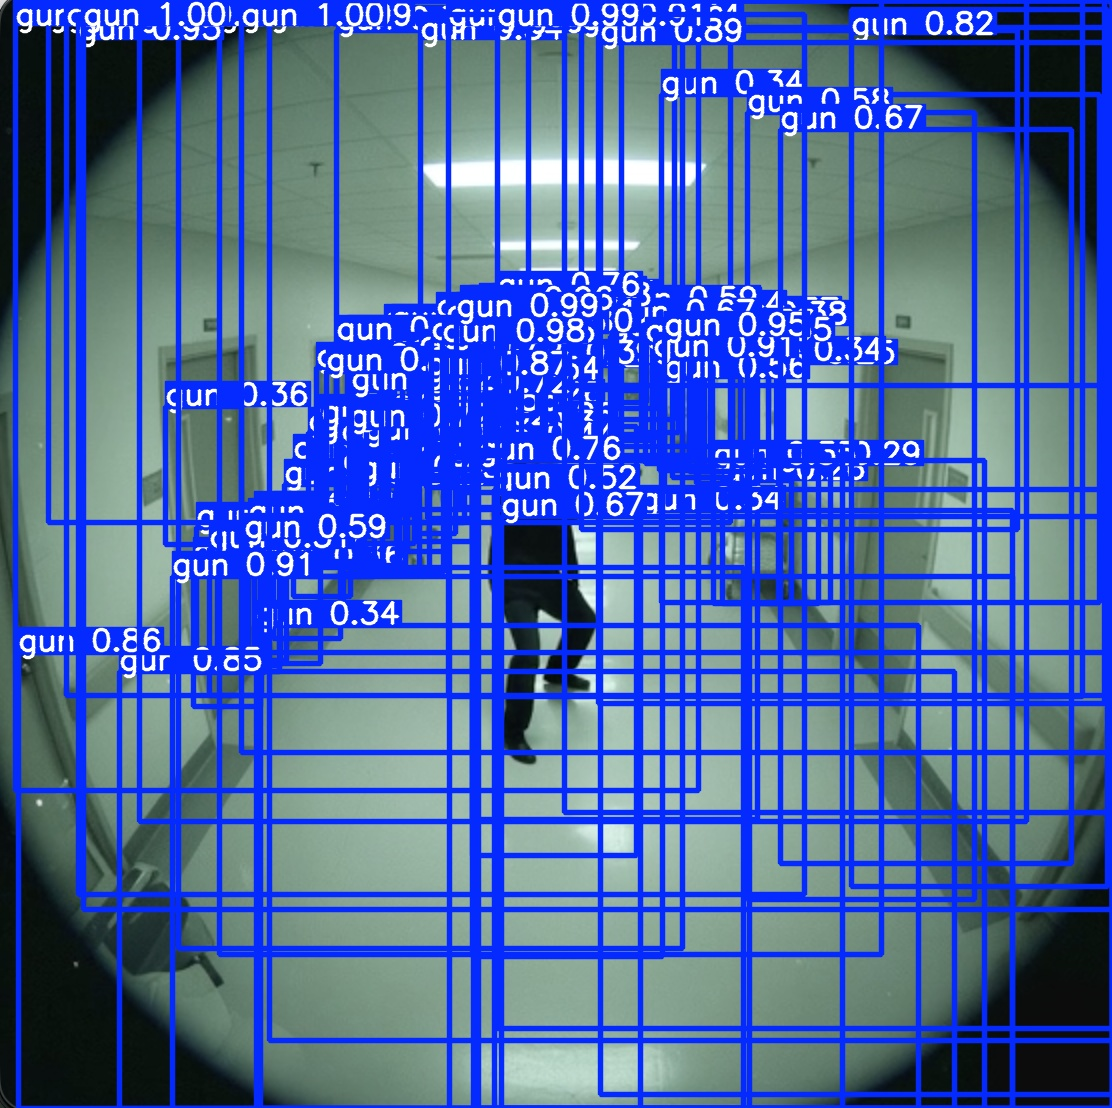

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import glob
from IPython.display import Image, display

root = Path.cwd()
runs_dir = root / "runs" / "detect"
train_candidates = [
    p for p in runs_dir.glob("gun_detector*")
    if (p / "weights" / "best.pt").exists()
]

if not train_candidates:
    raise FileNotFoundError(f"No trained model found under: {runs_dir}")

latest_run = max(train_candidates, key=lambda p: p.stat().st_mtime)
model_path = latest_run / "weights" / "best.pt"
source_dir = root / "dataset" / "images" / "val"
output_dir = runs_dir / "gun_detector_predict"

if not model_path.exists():
    raise FileNotFoundError(f"Model file not found: {model_path}")
if not source_dir.exists():
    raise FileNotFoundError(f"Validation image folder not found: {source_dir}")

model = YOLO(str(model_path))
model.predict(
    source=str(source_dir),
    save=True,
    name="gun_detector_predict",
    conf=0.5,
    iou=0.4,
    max_det=5,
    agnostic_nms=True,
)

for image_path in sorted(output_dir.glob("*.jpg"))[:1]:
    display(Image(filename=str(image_path), height=400))
    print('\n')
